# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()


Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [2]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


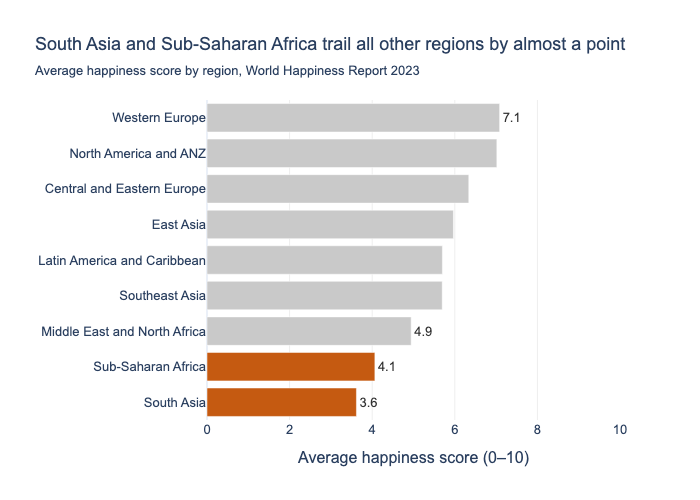

In [3]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar

print(region_avg)

# Step 2: Build your chart
low_regions = ['Sub-Saharan Africa', 'South Asia']
top_region = region_avg['Region'].iloc[-1]
next_region = region_avg.loc[~region_avg['Region'].isin(low_regions), 'Region'].iloc[0]

region_avg['Countries'] = region_avg['Region'].map(df['Region'].value_counts())
region_avg['Tier'] = region_avg['Region'].isin(low_regions).map({True: 'Low', False: 'Other'})
region_avg['Label'] = (region_avg['Happiness_Score'].map('{:.1f}'.format)
                       .where(region_avg['Region'].isin(low_regions + [next_region, top_region]), ''))

fig = px.bar(
    data_frame=region_avg,
    x='Happiness_Score', y='Region',
    orientation='h',
    color='Tier',
    color_discrete_map={'Low': '#C55A11', 'Other': '#C9C9C9'},
    text='Label',
    hover_data={'Happiness_Score': ':.2f', 'Countries': True, 'Tier': False, 'Label': False},
    labels={'Happiness_Score': 'Average happiness score (0–10)', 'Region': ''},
    range_x=[0, 10],
    template='plotly_white',
    height=500
)

fig.update_traces(textposition='outside', textfont=dict(color='#333333'), cliponaxis=False)

fig.update_layout(
    title=dict(
        text='South Asia and Sub-Saharan Africa trail all other regions by almost a point',
        subtitle=dict(text='Average happiness score by region, World Happiness Report 2023')
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', dtick=2),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(t=100)
)

fig.show()


---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81


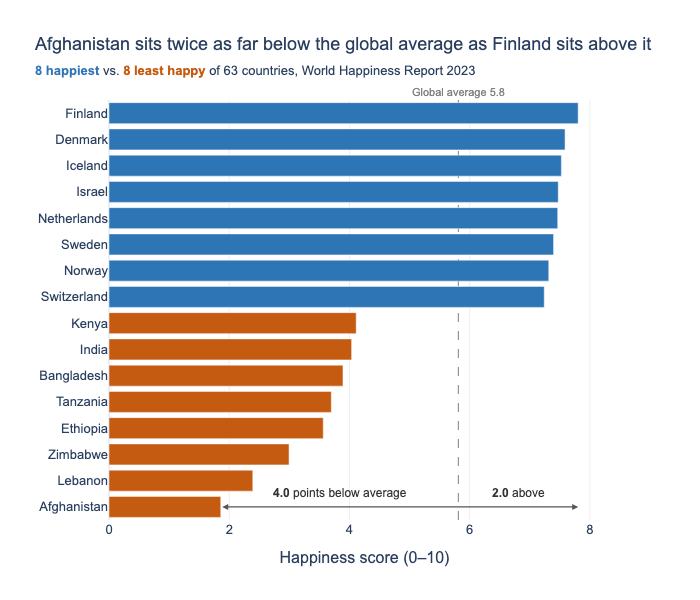

In [4]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build your chart
happiest = top8.iloc[0]
least_happy = bottom8.iloc[0]
above = happiest['Happiness_Score'] - global_avg
below = global_avg - least_happy['Happiness_Score']

fig = px.bar(
    data_frame=combined,
    x='Happiness_Score', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Top 8': '#2E75B6', 'Bottom 8': '#C55A11'},
    hover_data={'Region': True, 'Group': False, 'Happiness_Score': ':.2f'},
    labels={'Happiness_Score': 'Happiness score (0–10)', 'Country': ''},
    range_x=[0, 8.5],
    template='plotly_white',
    height=600
)

fig.add_vline(
    x=global_avg, layer='below',
    line_dash='dash', line_color='grey', line_width=1,
    annotation_text=f'Global average {global_avg:.1f}',
    annotation_position='top',
    annotation_font=dict(size=11, color='grey')
)

fig.add_annotation(
    x=happiest['Happiness_Score'], y=least_happy['Country'],
    ax=least_happy['Happiness_Score'], ay=least_happy['Country'],
    xref='x', yref='y', axref='x', ayref='y',
    text='', showarrow=True,
    arrowside='end+start', arrowhead=2, arrowsize=1, arrowwidth=1.2, arrowcolor='#555555'
)

for x_mid, label in [((least_happy['Happiness_Score'] + global_avg) / 2, f'<b>{below:.1f}</b> points below average'),
                     ((global_avg + happiest['Happiness_Score']) / 2, f'<b>{above:.1f}</b> above')]:
    fig.add_annotation(
        x=x_mid, y=least_happy['Country'], yshift=14,
        text=label, showarrow=False,
        font=dict(size=12, color='#333333')
    )

fig.update_layout(
    title=dict(
        text=f"{least_happy['Country']} sits twice as far below the global average as {happiest['Country']} sits above it",
        subtitle=dict(text=(
            "<span style='color:#2E75B6'><b>8 happiest</b></span> vs. "
            "<span style='color:#C55A11'><b>8 least happy</b></span> "
            f"of {len(df)} countries, World Happiness Report 2023"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', dtick=2),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(t=100)
)

fig.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


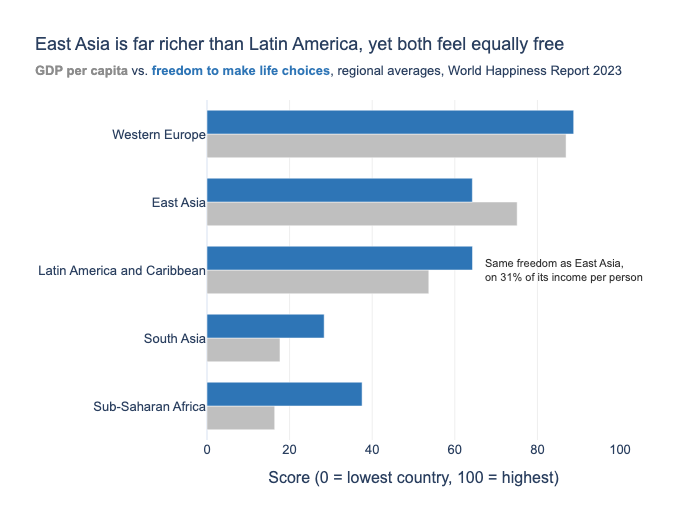

In [5]:
# Stretch goal — grouped bar chart
regions = ['Western Europe', 'Latin America and Caribbean', 'East Asia', 'Sub-Saharan Africa', 'South Asia']
factors = {'GDP': 'GDP per capita', 'Freedom': 'Freedom to make life choices'}

factor_values = df[list(factors)]
scaled = (factor_values - factor_values.min()) / (factor_values.max() - factor_values.min()) * 100

region_factors = (scaled.assign(Region=df['Region'])
                  .loc[lambda d: d['Region'].isin(regions)]
                  .groupby('Region').mean()
                  .sort_values('GDP')
                  .reset_index())

region_gdp = df.groupby('Region')['GDP'].mean()
income_ratio = np.exp(region_gdp['East Asia'] - region_gdp['Latin America and Caribbean'])

long = (region_factors.melt(id_vars='Region', var_name='Factor', value_name='Score')
        .assign(Factor=lambda d: d['Factor'].map(factors)))

fig = px.bar(
    data_frame=long,
    x='Score', y='Region',
    orientation='h',
    color='Factor',
    barmode='group',
    category_orders={'Factor': list(factors.values())},
    color_discrete_map={'GDP per capita': '#BFBFBF', 'Freedom to make life choices': '#2E75B6'},
    hover_data={'Score': ':.0f'},
    labels={'Score': 'Score (0 = lowest country, 100 = highest)', 'Region': ''},
    range_x=[0, 100],
    template='plotly_white',
    height=520
)

fig.add_annotation(
    x=region_factors.set_index('Region').loc['Latin America and Caribbean', 'Freedom'], y='Latin America and Caribbean',
    xanchor='left', xshift=10,
    text=f'Same freedom as East Asia,<br>on {1 / income_ratio:.0%} of its income per person',
    showarrow=False,
    align='left',
    font=dict(size=11, color='#333333')
)

fig.update_layout(
    title=dict(
        text='East Asia is far richer than Latin America, yet both feel equally free',
        subtitle=dict(text=(
            "<span style='color:#8C8C8C'><b>GDP per capita</b></span> vs. "
            "<span style='color:#2E75B6'><b>freedom to make life choices</b></span>, "
            "regional averages, World Happiness Report 2023"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', dtick=20),
    yaxis=dict(showgrid=False),
    showlegend=False,
    bargap=0.3,
    margin=dict(t=100)
)

fig.show()
